# 03 · Is KNN the right model? A fair comparison

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryammahmoudi1993/KNN_IRIS_classification/blob/main/notebooks/03_is_knn_the_right_model.ipynb)

**After this notebook you will be able to** compare several classifiers on exactly the same data split and the same cross-validation, read the differences against their spread, and explain why "no clear winner" is a valid result.

| | |
|---|---|
| Who it is for | Anyone who finished notebook `02`. |
| Time | About 40 minutes to read; the code runs in about 15 seconds on a CPU. |
| Random seed | `42` everywhere. |
| Next | `04` explains *why* KNN makes a given decision, with SHAP and LIME. |

## 1. The big question

We tuned KNN carefully in notebook 02. But maybe a different kind of model would do better on the same flowers. **How do we compare models fairly?** A comparison is only fair if every model sees the same training flowers, takes the same quizzes, and is judged on the same final exam.

## 2. Intuition first: a race on one track

Imagine a race between runners. It would be unfair if one runner ran on a flat track and another uphill, or if each had a different stopwatch. For models the "track" is the **data split**, the "stopwatch" is the **cross-validation**, and we need a slow baseline to know whether anyone is really running:

- **Baseline:** a runner who always answers with the most common species. On balanced Iris data that is right a third of the time. Any real model must beat this.
- **Contenders:** KNN (our model), logistic regression, a decision tree, an SVM, a random forest and Gaussian naive Bayes.

Each contender draws the boundary between species in a different *shape*:

| Model | Shape of its boundary |
|---|---|
| KNN | follows the nearby examples, any shape |
| Logistic regression | straight lines |
| Decision tree | rectangles aligned with the axes |
| SVM with an RBF kernel | smooth curves |

In [1]:
import os, pathlib, subprocess, sys

# On Google Colab the repository is not there yet, so we download it once.
if "google.colab" in sys.modules and not pathlib.Path("src").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/maryammahmoudi1993/KNN_IRIS_classification.git"], check=True)
    os.chdir("KNN_IRIS_classification/notebooks")

sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent))   # lets us import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.iris_knn import (SEED, FEATURES, CLASSES, load_iris_frame, split_data,
                          scatter_species, plot_decision_regions, save_figure)

np.random.seed(SEED)               # fixed seed: you will get the same numbers as the author
plt.rcParams["figure.dpi"] = 100

In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from src.iris_knn import make_model, repeated_cv

df = load_iris_frame()
x_train, x_test, y_train, y_test = split_data(df, test_size=0.2, seed=SEED)
cv = repeated_cv()              # 5 folds x 10 repeats, the same quizzes as in notebook 02
print("train:", x_train.shape, " test:", x_test.shape, " quizzes per model:", cv.get_n_splits())

train: (120, 4)  test: (30, 4)  quizzes per model: 50


Same split, same cross-validation as notebook 02. The test set stays in the drawer until the end.

## 3. A picture: four ways to draw the boundary

To draw a picture we use two features again (petal length and width). **Predict first:** which model will draw straight lines, and which will draw boxes?

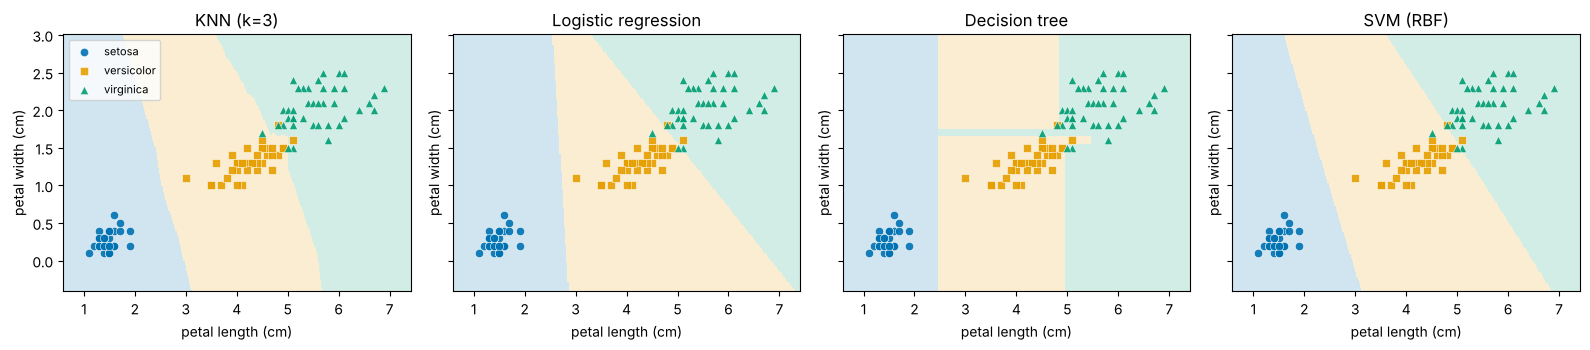

In [3]:
train_df = x_train.assign(species=y_train)
fx, fy = "petal length (cm)", "petal width (cm)"
two = [fx, fy]

shapes = {
    "KNN (k=3)": KNeighborsClassifier(n_neighbors=3),
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Decision tree": DecisionTreeClassifier(random_state=SEED),
    "SVM (RBF)": SVC(),
}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, (name, model) in zip(axes, shapes.items()):
    model.fit(train_df[two], train_df["species"])
    plot_decision_regions(ax, model, train_df, fx, fy, title=name)
axes[0].legend(fontsize=8, loc="upper left")
fig.tight_layout()
save_figure(fig, "03_model_regions.png")
plt.show()

*Figure 1. What to notice:* logistic regression cuts the plane with straight lines, the tree with axis-aligned boxes, the SVM with smooth curves, and KNN follows the points. All four agree on the big picture: *setosa* is far away and easy; the border between *versicolor* and *virginica* is where they differ a little.

## 4. A little math

Each model turns four measurements into a species in its own way. The simplest to write down is **logistic regression** for three classes:

$$P(\text{class } c \mid x) = \frac{e^{z_c}}{\sum_{j} e^{z_j}}, \qquad z_c = w_c \cdot x + b_c$$

- $x$ is the vector of four measurements of one flower.
- $w_c$ and $b_c$ are numbers the model *learns* for class $c$ (one weight per measurement, plus an offset).
- $z_c$ is a score for class $c$; the fraction turns the three scores into probabilities that add up to 1.

KNN has no such formula: it keeps the flowers and votes. That difference (parameters learned versus examples remembered) is the main idea behind everything in this notebook.

## 5. The race

First the baseline. **Predict first:** what accuracy does a model get if it always names the most common species?

In [4]:
baseline = DummyClassifier(strategy="most_frequent")
base_scores = cross_val_score(baseline, x_train, y_train, cv=cv)
print(f"baseline accuracy over {len(base_scores)} quizzes: {base_scores.mean():.3f}")

baseline accuracy over 50 quizzes: 0.333


One third, as expected for three balanced species. Now the real contenders. We keep scikit-learn's default settings, except that KNN uses the `k=3` we chose in notebook 02 and the models that need it get standardised features.

In [5]:
models = {
    "Majority class (baseline)": DummyClassifier(strategy="most_frequent"),
    "KNN (k=3)": make_model(k=3),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision tree": DecisionTreeClassifier(random_state=SEED),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC()),
    "Random forest": RandomForestClassifier(random_state=SEED),
    "Gaussian naive Bayes": GaussianNB(),
}

scores = {name: cross_val_score(model, x_train, y_train, cv=cv) for name, model in models.items()}
table = pd.DataFrame({
    "mean accuracy": {n: s.mean() for n, s in scores.items()},
    "spread": {n: s.std() for n, s in scores.items()},
}).round(4)
table

,mean accuracy,spread
Majority class (baseline),0.3333,0.0000
KNN (k=3),0.9550,0.0407
Logistic regression,0.9600,0.0322
Decision tree,0.9425,0.0432
SVM (RBF),0.9642,0.0354
Random forest,0.9508,0.0370
Gaussian naive Bayes,0.9533,0.0319


Every real model sits between 0.94 and 0.97, far above the baseline of 0.33. Look at the `spread` column too: it is about 0.03 to 0.04 for all of them.

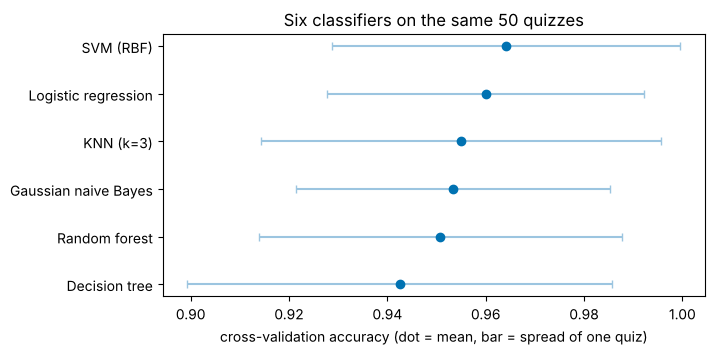

In [6]:
real = table.drop(index="Majority class (baseline)").sort_values("mean accuracy")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.errorbar(real["mean accuracy"], range(len(real)), xerr=real["spread"], fmt="o", color="#0072B2",
            ecolor="#9CC5E0", capsize=3)
ax.set_yticks(range(len(real)))
ax.set_yticklabels(real.index)
ax.set_xlabel("cross-validation accuracy (dot = mean, bar = spread of one quiz)")
ax.set_title("Six classifiers on the same 50 quizzes")
save_figure(fig, "03_cv_comparison.png")
plt.show()

*Figure 2. What to notice:* the bars overlap almost completely. From the lowest dot to the highest is about two percentage points, which is less than the width of one bar.

## 6. Paired differences

All models took the *same* 50 quizzes, so we can subtract their grades quiz by quiz and look at the difference to KNN. This removes the "easy quiz, hard quiz" effect that hits everyone alike.

In [7]:
knn_scores = scores["KNN (k=3)"]
diff = pd.DataFrame({
    "mean difference to KNN": {n: (s - knn_scores).mean() for n, s in scores.items()},
    "spread of the difference": {n: (s - knn_scores).std() for n, s in scores.items()},
}).drop(index=["KNN (k=3)", "Majority class (baseline)"]).round(4)
diff

,mean difference to KNN,spread of the difference
Logistic regression,0.0050,0.0308
Decision tree,-0.0125,0.0515
SVM (RBF),0.0092,0.0225
Random forest,-0.0042,0.0375
Gaussian naive Bayes,-0.0017,0.0353


Each mean difference is smaller than 0.015, while the spread of the difference is 0.02 to 0.05. In plain words: **sometimes the other model wins a quiz, sometimes KNN does, and the average edge is tiny.**

(We do not compute a p-value here. The 50 quizzes reuse the same 120 flowers, so they are not independent, and a p-value would look more certain than it is.)

## 7. Open the drawer

In [8]:
rows = []
for name, model in models.items():
    model.fit(x_train, y_train)
    correct = int((model.predict(x_test) == y_test).sum())
    rows.append({"model": name, "CV accuracy": round(scores[name].mean(), 3),
                 "test flowers correct": f"{correct} / {len(y_test)}"})
final = pd.DataFrame(rows).set_index("model")
final

,CV accuracy,test flowers correct
model,,
Majority class (baseline),0.333,10 / 30
KNN (k=3),0.955,28 / 30
Logistic regression,0.960,28 / 30
Decision tree,0.943,28 / 30
SVM (RBF),0.964,29 / 30
Random forest,0.951,27 / 30
Gaussian naive Bayes,0.953,29 / 30


On the 30 test flowers the real models get 27 to 29 right. One flower is 3.3 points, so these differences are **within one or two flowers**, which is exactly what the cross-validation told us. The test set confirms the story but cannot rank the models.

## 8. What should we conclude?

- All six models solve Iris about equally well. **Accuracy alone does not choose a winner here.**
- So choose on other grounds: simplicity, speed, how easy the model is to explain, how it behaves when the data grows.
- KNN's strengths: no training step, an explanation that anyone understands ("these three flowers look alike"). Its weaknesses: it must keep all the data and compare every new flower with all of it, and it depends on feature scales.

A fairness note: KNN's `k` was chosen by cross-validation on this same training set, while the other models use default settings. That gives KNN a very small head start. It would not change the conclusion, but we say it.

## 9. Check yourself

**Question 1.** Model A scores 0.962 and model B scores 0.955 in cross-validation, each with a spread of 0.04. Which is better?

<details>
<summary>Show the answer</summary>

We cannot tell. The 0.007 gap is much smaller than the spread of 0.04, so the data do not support a winner. We would need more data or a larger gap.

</details>

**Question 2.** Why is the baseline useful even though nobody would deploy it?

<details>
<summary>Show the answer</summary>

It shows what accuracy is worth doing nothing clever. With balanced classes it is 0.33; a model near that number has learned nothing. On unbalanced data the baseline can be very high, and then 'accuracy' alone is misleading.

</details>

**Question 3 (exercise).** Add `LogisticRegression(C=0.1)` to the `models` dictionary and re-run sections 5 to 7. Does the ranking change in a way that matters?

<details>
<summary>Show the answer</summary>

The mean will move by a fraction of a point, far less than the spread. Tuning one model more than the others can change a ranking by a little, which is why we keep tuning equal or say clearly when it is not.

</details>

## 10. Common mistakes

- **Different splits for different models.** Then you compare luck, not models.
- **Tuning one model heavily and leaving the others at defaults** without saying so.
- **Reading small gaps as winners.** Compare gaps to the spread.
- **Picking the model with the best test score.** That uses the test set to choose, as in notebook 02.

## 11. Recap

- A fair comparison uses the **same split, the same cross-validation and a baseline**.
- On Iris all real models score about 0.94 to 0.96 (spread about 0.03 to 0.04): **no model clearly wins**.
- When accuracy ties, choose by simplicity and by how well you can **explain** the decisions.

**Next, in notebook 04:** KNN's decisions can be explained by its neighbours. We compare that with permutation importance, SHAP and LIME, and look at the two flowers it got wrong.

### Further reading
- scikit-learn user guide, *Cross-validation* and *Metrics and scoring*: https://scikit-learn.org/stable/modules/cross_validation.html
- scikit-learn user guide, *Supervised learning* (the model descriptions): https://scikit-learn.org/stable/supervised_learning.html
- scikit-learn, *DummyClassifier*: https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html